# Driver Drowsiness Detection: Random Forest vs KNN vs CNN

**Goal:** decide from a driver's face whether they are **Drowsy** or **Alert (Non Drowsy)**.

**Tools used:** OpenCV, MediaPipe (face landmarks), NumPy, scikit-learn, PyTorch.

**Data:** Kaggle *Driver Drowsiness Dataset (DDD)*: 41,793 face images of 28 drivers.

| # | Model | Input |
|---|---|---|
| 1 | **Random Forest** | facial measurements from MediaPipe: EAR (eye opening), MAR (mouth opening), head tilt, eye blink / squint / gaze, jaw open |
| 2 | **KNN** | the same measurements (scaled) |
| 3 | **CNN (PyTorch)** | the face image itself (64×64 grayscale) |

**Fair test:** the data is split **by driver**. The test drivers are never seen in training, so the models can't just memorise faces.

**Run:** Runtime → Change runtime type → **GPU** (optional, makes the CNN faster) → **Run all**. It takes about 5 minutes.

## 1. Setup

In [1]:
%pip install -q kagglehub

In [2]:
import os, random, time, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import cv2, joblib, kagglehub
import torch, torch.nn as nn
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
sns.set_theme(style="whitegrid")
print("device:", device)

device: cpu


## 2. Load the data
The CSV holds one row per image. The measurements were extracted with **MediaPipe Face Landmarker** (468 face points → EAR, MAR, head pose, eye blink scores).

**EAR** (eye aspect ratio) = (‖p2−p6‖ + ‖p3−p5‖) / (2‖p1−p4‖). It is about 0.3 for an open eye and close to 0 for a closed eye.
**MAR** (mouth aspect ratio) works the same way for the mouth and rises when yawning.

In [3]:
CSV_URL = "https://raw.githubusercontent.com/annyaaggarwal501-netizen/Driver-s-Drowsiness-Detector/main/data/driver_drowsiness_features.csv"
df = pd.read_csv(CSV_URL)

FEATURES = ["ear_left", "ear_right", "mar", "mouth_open", "head_pitch", "head_yaw", "head_roll",
            "eye_blink_left", "eye_blink_right", "eye_squint_left", "eye_squint_right",
            "gaze_down_left", "gaze_down_right", "jaw_open"]
df = df.dropna(subset=FEATURES).reset_index(drop=True)      # 4 images had no face detected
df["y"] = (df["label"] == "Drowsy").astype(int)            # 1 = Drowsy, 0 = Non Drowsy
print(df.shape)
df[["image", "subject_id", "label"] + FEATURES[:4]].head()

(41789, 30)


,image,subject_id,label,ear_left,ear_right,mar,mouth_open
0,A0001.png,A,Drowsy,0.24703,0.23590,0.00796,0.00378
1,A0002.png,A,Drowsy,0.26246,0.26242,0.00599,0.00251
2,A0003.png,A,Drowsy,0.28051,0.28119,0.00544,0.00168
3,A0004.png,A,Drowsy,0.29914,0.29036,0.00726,0.00295
4,A0005.png,A,Drowsy,0.34391,0.34174,0.00664,0.00241


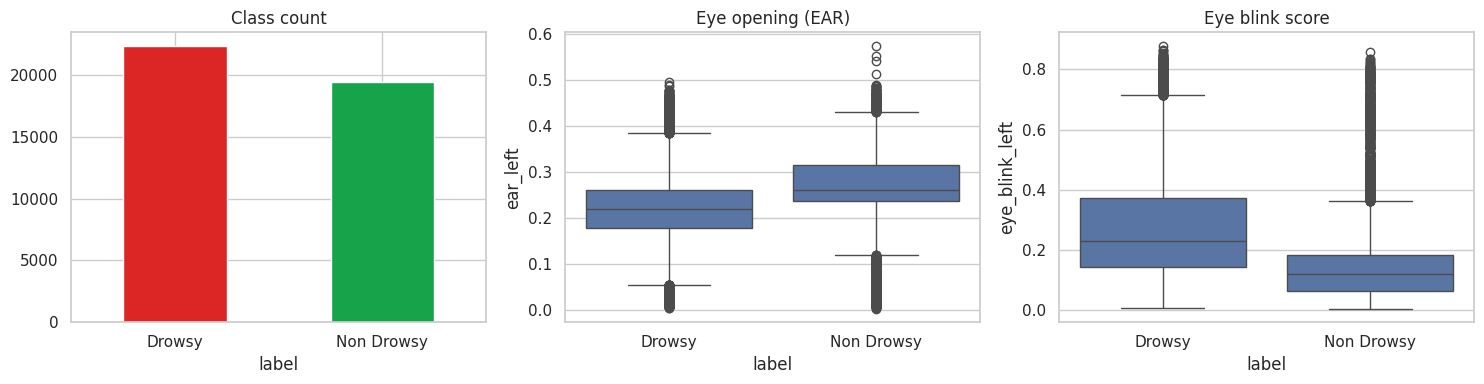

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df["label"].value_counts().plot.bar(ax=axes[0], color=["#dc2626", "#16a34a"], rot=0, title="Class count")
sns.boxplot(data=df, x="label", y="ear_left", ax=axes[1]); axes[1].set_title("Eye opening (EAR)")
sns.boxplot(data=df, x="label", y="eye_blink_left", ax=axes[2]); axes[2].set_title("Eye blink score")
plt.tight_layout(); plt.show()

## 3. Split by driver (no leakage)
About 20 % of the drivers go to the test set with all their images. Random image splitting would put almost identical frames of the same person in both train and test, giving fake ~99 % accuracy.

In [5]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(gss.split(df, df["y"], df["subject_id"]))
train, test = df.iloc[train_idx], df.iloc[test_idx]
print("train drivers:", sorted(train["subject_id"].unique()), len(train), "images")
print("test drivers :", sorted(test["subject_id"].unique()), len(test), "images")
assert not set(train["subject_id"]) & set(test["subject_id"])

X_train, y_train = train[FEATURES], train["y"]
X_test, y_test = test[FEATURES], test["y"]

results, cms = {}, {}
def evaluate(name, y_true, y_pred):
    results[name] = {"Accuracy": accuracy_score(y_true, y_pred), "Precision": precision_score(y_true, y_pred),
                     "Recall": recall_score(y_true, y_pred), "F1-Score": f1_score(y_true, y_pred)}
    cms[name] = confusion_matrix(y_true, y_pred)
    print(name, {k: f"{v:.2%}" for k, v in results[name].items()})

train drivers: ['B', 'C', 'D', 'E', 'F', 'G', 'H', 'K', 'L', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'W', 'X', 'Y', 'ZB', 'ZC'] 31215 images
test drivers : ['A', 'I', 'J', 'M', 'V', 'ZA'] 10574 images


## 4. Model 1: Random Forest

Random Forest {'Accuracy': '69.14%', 'Precision': '66.14%', 'Recall': '72.01%', 'F1-Score': '68.95%'}
trained in 39.8 s


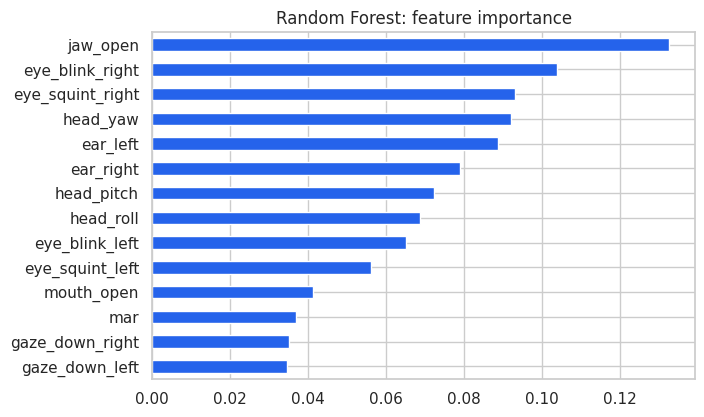

In [6]:
t0 = time.time()
rf = RandomForestClassifier(n_estimators=200, max_depth=15, min_samples_leaf=5, class_weight="balanced",
                            n_jobs=-1, random_state=SEED)
rf.fit(X_train, y_train)
evaluate("Random Forest", y_test, rf.predict(X_test))
print(f"trained in {time.time() - t0:.1f} s")

imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
imp.plot.barh(figsize=(7, 4.5), color="#2563eb", title="Random Forest: feature importance"); plt.show()

## 5. Model 2: K-Nearest Neighbours
KNN compares distances, so the features are scaled first (StandardScaler).

In [7]:
t0 = time.time()
knn = Pipeline([("scale", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=25, n_jobs=-1))])
knn.fit(X_train, y_train)
evaluate("KNN", y_test, knn.predict(X_test))
print(f"trained in {time.time() - t0:.1f} s")

KNN {'Accuracy': '74.27%', 'Precision': '69.42%', 'Recall': '82.05%', 'F1-Score': '75.21%'}
trained in 3.5 s


## 6. Model 3: CNN (PyTorch) on face images
The images come from Kaggle with `kagglehub` (about 2.6 GB). Each face is resized to 64×64 grayscale. Every 2nd training frame is used (neighbouring frames are almost identical), and the test set is exactly the same test images as for the other two models.

Using Colab cache for faster access to the 'driver-drowsiness-dataset-ddd' dataset.
loaded 15608 train + 10574 test images in 339 s


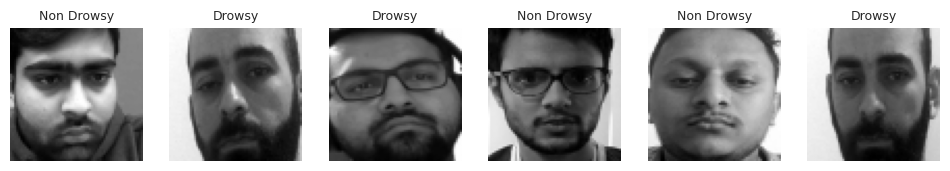

In [8]:
ROOT = os.path.join(kagglehub.dataset_download("ismailnasri20/driver-drowsiness-dataset-ddd"), "Driver Drowsiness Dataset (DDD)")
IMG = 64

def load_images(rows):
    imgs = np.zeros((len(rows), IMG, IMG), dtype=np.uint8)
    for i, (name, label) in enumerate(zip(rows["image"], rows["label"])):
        img = cv2.imread(os.path.join(ROOT, label, name), cv2.IMREAD_GRAYSCALE)
        imgs[i] = cv2.resize(img, (IMG, IMG), interpolation=cv2.INTER_AREA)
    return imgs

t0 = time.time()
train_small = train.iloc[::2]
Xtr_img, ytr_img = load_images(train_small), train_small["y"].to_numpy()
Xte_img, yte_img = load_images(test), test["y"].to_numpy()
print(f"loaded {len(Xtr_img)} train + {len(Xte_img)} test images in {time.time() - t0:.0f} s")

fig, axes = plt.subplots(1, 6, figsize=(12, 2.4))
for ax, i in zip(axes, np.random.choice(len(Xtr_img), 6, replace=False)):
    ax.imshow(Xtr_img[i], cmap="gray"); ax.set_title("Drowsy" if ytr_img[i] else "Non Drowsy", fontsize=9); ax.axis("off")
plt.show()

epoch 1: loss 0.328  test accuracy 61.82%
epoch 2: loss 0.063  test accuracy 65.25%
epoch 3: loss 0.036  test accuracy 68.92%
epoch 4: loss 0.027  test accuracy 62.81%
epoch 5: loss 0.018  test accuracy 68.56%
epoch 6: loss 0.019  test accuracy 65.04%
epoch 7: loss 0.014  test accuracy 69.21%
epoch 8: loss 0.022  test accuracy 58.42%
trained in 826 s


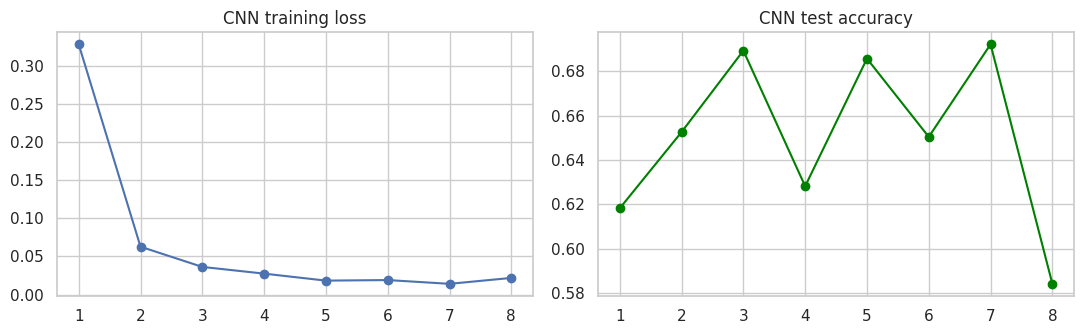

CNN {'Accuracy': '58.42%', 'Precision': '53.68%', 'Recall': '91.93%', 'F1-Score': '67.78%'}


In [9]:
class DrowsyCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),   # 64 -> 32
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),  # 32 -> 16
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),  # 16 -> 8
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(64 * 8 * 8, 64), nn.ReLU(), nn.Dropout(0.5), nn.Linear(64, 2))

    def forward(self, x):
        return self.classifier(self.features(x))

to_tensor = lambda a: torch.tensor(a, dtype=torch.float32).unsqueeze(1) / 255.0
Xtr_t, ytr_t = to_tensor(Xtr_img), torch.tensor(ytr_img)
Xte_t = to_tensor(Xte_img)

cnn = DrowsyCNN().to(device)
optimizer = torch.optim.Adam(cnn.parameters(), lr=1e-3, weight_decay=1e-4)
loss_fn = nn.CrossEntropyLoss()
EPOCHS, BATCH = 8, 128

def predict_cnn(X):
    cnn.eval(); preds = []
    with torch.no_grad():
        for i in range(0, len(X), 512):
            preds.append(cnn(X[i:i + 512].to(device)).argmax(1).cpu())
    return torch.cat(preds).numpy()

history = []
t0 = time.time()
for epoch in range(EPOCHS):
    cnn.train(); perm = torch.randperm(len(Xtr_t)); total = 0.0
    for i in range(0, len(perm), BATCH):
        idx = perm[i:i + BATCH]
        xb, yb = Xtr_t[idx], ytr_t[idx]
        if random.random() < 0.5:
            xb = torch.flip(xb, dims=[3])                                   # augmentation: mirror
        xb = (xb * (0.8 + 0.4 * torch.rand(len(xb), 1, 1, 1))).clamp(0, 1)   # augmentation: brightness
        optimizer.zero_grad()
        loss = loss_fn(cnn(xb.to(device)), yb.to(device))
        loss.backward(); optimizer.step(); total += loss.item() * len(idx)
    test_acc = accuracy_score(yte_img, predict_cnn(Xte_t))
    history.append({"epoch": epoch + 1, "loss": total / len(perm), "test_acc": test_acc})
    print(f"epoch {epoch + 1}: loss {total / len(perm):.3f}  test accuracy {test_acc:.2%}")
print(f"trained in {time.time() - t0:.0f} s")

h = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(h["epoch"], h["loss"], marker="o"); axes[0].set_title("CNN training loss")
axes[1].plot(h["epoch"], h["test_acc"], marker="o", color="green"); axes[1].set_title("CNN test accuracy")
plt.tight_layout(); plt.show()

evaluate("CNN", yte_img, predict_cnn(Xte_t))

## 7. Comparison of the 3 models
All three are tested on the **same images of the same unseen drivers**.

,Accuracy,Precision,Recall,F1-Score
Random Forest,69.14%,66.14%,72.01%,68.95%
KNN,74.27%,69.42%,82.05%,75.21%
CNN,58.42%,53.68%,91.93%,67.78%


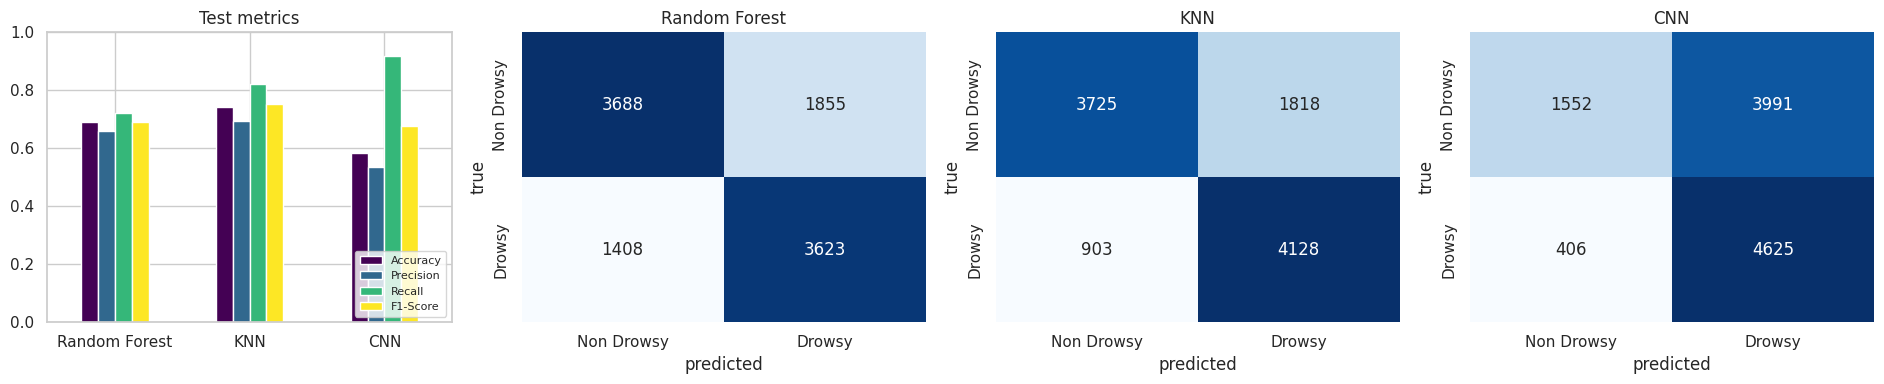

BEST MODEL: KNN  (F1 75.21%, accuracy 74.27%)


In [10]:
table = pd.DataFrame(results).T
display(table.style.format("{:.2%}").background_gradient(cmap="Greens"))

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
table.plot.bar(ax=axes[0], rot=0, ylim=(0, 1), title="Test metrics", colormap="viridis")
axes[0].legend(fontsize=8, loc="lower right")
for ax, (name, cm) in zip(axes[1:], cms.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Non Drowsy", "Drowsy"], yticklabels=["Non Drowsy", "Drowsy"])
    ax.set_title(name); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()

best = table["F1-Score"].idxmax()
print(f"BEST MODEL: {best}  (F1 {table.loc[best, 'F1-Score']:.2%}, accuracy {table.loc[best, 'Accuracy']:.2%})")

## 8. Save the models (for the Streamlit app)

In [11]:
joblib.dump(rf, "rf_model.pkl")
joblib.dump(knn, "knn_model.pkl")
torch.save(cnn.state_dict(), "cnn_model.pt")
with open("model_info.json", "w") as f:
    json.dump({"features": FEATURES, "img_size": IMG, "labels": ["Non Drowsy", "Drowsy"],
               "results": table.round(4).to_dict(orient="index"), "best_model": best}, f, indent=2)
print("saved: rf_model.pkl, knn_model.pkl, cnn_model.pt, model_info.json")

try:                                   # download the files when running in Google Colab
    from google.colab import files
    for f in ["rf_model.pkl", "knn_model.pkl", "cnn_model.pt", "model_info.json"]:
        files.download(f)
except ImportError:
    pass

saved: rf_model.pkl, knn_model.pkl, cnn_model.pt, model_info.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Conclusion
* **Random Forest** and **KNN** use the facial measurements (EAR, MAR, head pose, blink scores) that MediaPipe extracts. Random Forest's feature importance shows which signs matter most.
* The **CNN** learns directly from the face image, with no hand-made features.
* Because the test drivers were never seen in training, these scores show how the models would work on a **new driver**.
* **Next step:** a Streamlit app loads the saved models and runs them live on the webcam (OpenCV + MediaPipe).